<h1 style="text-align:center">
    Movies
</h1>

<br>

<font color="darkblue">

<h3 style="text-align:center">
    Pedro Pablo Vicente González
</h3>
    
<h3 style="text-align:center">
    10-04-2025
</h3>

<hr>

# Introducción

<br>

En este proyecto se desarrolla en Python un análisis básico de datos sobre películas de cine de IMDB.
El set de datos que vamos a usar inicialmente se encuentra en la siguiente página:

https://www.kaggle.com/datasets/carolzhangdc/imdb-5000-movie-dataset

En ella puede encontrarse información más detallada, así como una descripción precisa de cada columna.

</font>

<br>

Se plantean los apartados iniciales para su resolución *sin usar la libreria pandas*. Esto se propone así para forzar a practicar con las técnicas, herramientas y conceptos básicos de Python. Más adelante, hay otros apartados propuestos para su resolución con esta librería y otras.

<br>

<font color="darkblue">
A partir de los datos proporcionados, he conseguido resolver todos los ejercicios de forma satisfactoria. Los resultados aportados son, si no idénticos, similares a los proporcionados por las muestras de salida esperada. 

<br>

En lo general, si bien creo que estos problemas no son relevantes a la hora de calificar mi trabajo, he tratado de ceñirme a los resultados de las salidas esperadas en base a los test de funcionamiento (he agradecido ejercicios como el B4, en el que no lo hay). Todos los códigos han sido comentados mediante docstrings en base al sistema de anotación PEP-8, por lo que espero no haya problemas de lectura.

<br>
Aunque al final de este notebook detallaré la calificación que calculo honestamente, globalmente, siguiendo las puntuaciones que se asigna a cada apartado, diría que he obtenido una nota de 9 sobre 10.
</font>


# Datos de partida

(**Nota previa:** hasta el apartado específico de dataframes, se deben desarrollar las soluciones a los ejercicios propuestos sin usar la librería `pandas`, justamente para obligar a practicar con conceptos básicos de Python.)

Nuestra tabla de datos es un archivo de texto (`ds_salaries.csv`) que puede verse así con cualquier editor:

<br>

<center>
    <img src="./images/texto.png" width="100%">
</center>

La primera fila es la cabecera.
Esta fila cabecera contiene los nombres de los campos, separados por comas.
Yo la he marcado en azul para distinguirla fácilmente de las demás filas, que contienen los datos propiamente dichos,
esto es, los valores de dichos campos, consignando los datos de cada película en cada línea.

Si abrimos esta tabla con *excell* (importar datos csv con el separador `,`), vemos cada dato en una celda.

<br>

<center>
    <img src="./images/csv_1.png" width="100%">
</center>

<br>

Mostramos la hoja excell en dos imágenes por ser muy ancha.

<br>

<center>
    <img src="./images/csv_2.png" width="100%">
</center>

# Librerías y constantes globales

<br>

Pongamos todas las librerías necesarias al principio, tal como propone el estilo `pep-8`. Ej.:
<a href="https://www.python.org/dev/peps/pep-0008/">PEP 8 -- Style Guide for Python Code</a>.
    
De paso, en éste y otros lugares de Internet podrás encontrar detalles sobre estilo y presentación de código con un estilo estándar y cuidado. Examina esta página y trata de seguir esas indicaciones.

In [3]:
# Librerías:

# Esta celda debe ser completada por el estudiante

import csv
from collections import defaultdict
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup
import requests
import pandas as pd
from functools import reduce

In [4]:
# Constantes globales:

# Esta celda debe ser completada por el estudiante

MOVIES_DATA = r"C:\Users\ppabl\Desktop\TAREA PYTHON\data_in\movie_data.csv"

FEW_FIELDS = r"C:\Users\ppabl\Desktop\TAREA PYTHON\data_in\algunos_campos.txt"

# Parte A. Ejercicios básicos sin usar `pandas` [2 puntos]

Esta parte inicial debe realizarse sin usar la librería `pandas`. Para practicar con esta librería, se plantean otros apartados más abajo.

### A.1. Exploración inicial básica del archivo de datos

Deseamos cargar el archivo de datos, que tiene un formato `csv`.
En este apartado, te recomiendo fuertemente usar la librería `cvs`,
que deberás importar en la primera celda del script, más arriba, no aquí.
(En los siguientes apartados, ya no mencionaré qué librerías usar
ni recordaré dónde se han de importar.)

Observa también que el test de funcionamiento te da el nombre de la función que deber definir
y algún otro identificador como es, por ejemplo, la constante `MOVIES_DATA`,
que debes definir también más arriba, en la segunda celda de este script.

Finalmente, observando el test, verás que se carga por separado la cabecera y las filas de datos.

In [5]:
# Esta celda debe ser completada por el estudiante

def load_full_data(file_path):
    """
    Carga archivo de datos CSV.
    
    Parámetros:
        file_path: ruta del archivo CSV que abrir.
    
    Devuelve:
        full_header: cabeceras de cada columna del archivo.
        full_list_data: filas (muestras) con información sobre cada campo de full_header.
    """
    with open(file_path, newline='', encoding='utf-8') as archivo_csv:
        reader = csv.reader(archivo_csv, delimiter=',', quotechar='"')
        full_header = next(reader)    # next() consigue el título de columna
        full_list_data = list(reader) # list() consigue el resto de filas (los datos)
    return full_header, full_list_data



In [6]:
# Test de funcionamiento

full_header, full_list_data = load_full_data(MOVIES_DATA)

print(full_header)
print()
print(full_list_data[0:5])

['color', 'director_name', 'num_critic_for_reviews', 'duration', 'director_facebook_likes', 'actor_3_facebook_likes', 'actor_2_name', 'actor_1_facebook_likes', 'gross', 'genres', 'actor_1_name', 'movie_title', 'num_voted_users', 'cast_total_facebook_likes', 'actor_3_name', 'facenumber_in_poster', 'plot_keywords', 'movie_imdb_link', 'num_user_for_reviews', 'language', 'country', 'content_rating', 'budget', 'title_year', 'actor_2_facebook_likes', 'imdb_score', 'aspect_ratio', 'movie_facebook_likes']

[['Color', 'James Cameron', '723', '178', '0', '855', 'Joel David Moore', '1000', '760505847', 'Action|Adventure|Fantasy|Sci-Fi', 'CCH Pounder', 'Avatar\xa0', '886204', '4834', 'Wes Studi', '0', 'avatar|future|marine|native|paraplegic', 'http://www.imdb.com/title/tt0499549/?ref_=fn_tt_tt_1', '3054', 'English', 'USA', 'PG-13', '237000000', '2009', '936', '7.9', '1.78', '33000'], ['Color', 'Gore Verbinski', '302', '169', '563', '1000', 'Orlando Bloom', '40000', '309404152', 'Action|Adventure|F

Salida esperada:

    ['color', 'director_name', 'num_critic_for_reviews', 'duration', 'director_facebook_likes', 'actor_3_facebook_likes', 'actor_2_name', 'actor_1_facebook_likes', 'gross', 'genres', 'actor_1_name', 'movie_title', 'num_voted_users', 'cast_total_facebook_likes', 'actor_3_name', 'facenumber_in_poster', 'plot_keywords', 'movie_imdb_link', 'num_user_for_reviews', 'language', 'country', 'content_rating', 'budget', 'title_year', 'actor_2_facebook_likes', 'imdb_score', 'aspect_ratio', 'movie_facebook_likes']

    [['Color', 'James Cameron', '723', '178', '0', '855', 'Joel David Moore', '1000', '760505847', 'Action|Adventure|Fantasy|Sci-Fi', 'CCH Pounder', 'Avatar\xa0', '886204', '4834', 'Wes Studi', '0', 'avatar|future|marine|native|paraplegic', 'http://www.imdb.com/title/tt0499549/?ref_=fn_tt_tt_1', '3054', 'English', 'USA', 'PG-13', '237000000', '2009', '936', '7.9', '1.78', '33000'], ['Color', 'Gore Verbinski', '302', '169', '563', '1000', 'Orlando Bloom', '40000', '309404152', 'Action|Adventure|Fantasy', 'Johnny Depp', "Pirates of the Caribbean: At World's End\xa0", '471220', '48350', 'Jack Davenport', '0', 'goddess|marriage ceremony|marriage proposal|pirate|singapore', 'http://www.imdb.com/title/tt0449088/?ref_=fn_tt_tt_1', '1238', 'English', 'USA', 'PG-13', '300000000', '2007', '5000', '7.1', '2.35', '0'], ['Color', 'Sam Mendes', '602', '148', '0', '161', 'Rory Kinnear', '11000', '200074175', 'Action|Adventure|Thriller', 'Christoph Waltz', 'Spectre\xa0', '275868', '11700', 'Stephanie Sigman', '1', 'bomb|espionage|sequel|spy|terrorist', 'http://www.imdb.com/title/tt2379713/?ref_=fn_tt_tt_1', '994', 'English', 'UK', 'PG-13', '245000000', '2015', '393', '6.8', '2.35', '85000'], ['Color', 'Christopher Nolan', '813', '164', '22000', '23000', 'Christian Bale', '27000', '448130642', 'Action|Thriller', 'Tom Hardy', 'The Dark Knight Rises\xa0', '1144337', '106759', 'Joseph Gordon-Levitt', '0', 'deception|imprisonment|lawlessness|police officer|terrorist plot', 'http://www.imdb.com/title/tt1345836/?ref_=fn_tt_tt_1', '2701', 'English', 'USA', 'PG-13', '250000000', '2012', '23000', '8.5', '2.35', '164000'], ['', 'Doug Walker', '', '', '131', '', 'Rob Walker', '131', '', 'Documentary', 'Doug Walker', 'Star Wars: Episode VII - The Force Awakens\xa0            ', '8', '143', '', '0', '', 'http://www.imdb.com/title/tt5289954/?ref_=fn_tt_tt_1', '', '', '', '', '', '', '12', '7.1', '', '0']]

    

Ahora, querríamos ver las posiciones de los identificadores de los campos, dados en la línea cabecera.

In [7]:
# Esta celda debe ser completada por el estudiante

list_of_enumerated_headers = list(enumerate(full_header)) # Ofrece el índice y valor de la cabecera.


In [8]:
# Test de funcionamiento

print(list_of_enumerated_headers)

[(0, 'color'), (1, 'director_name'), (2, 'num_critic_for_reviews'), (3, 'duration'), (4, 'director_facebook_likes'), (5, 'actor_3_facebook_likes'), (6, 'actor_2_name'), (7, 'actor_1_facebook_likes'), (8, 'gross'), (9, 'genres'), (10, 'actor_1_name'), (11, 'movie_title'), (12, 'num_voted_users'), (13, 'cast_total_facebook_likes'), (14, 'actor_3_name'), (15, 'facenumber_in_poster'), (16, 'plot_keywords'), (17, 'movie_imdb_link'), (18, 'num_user_for_reviews'), (19, 'language'), (20, 'country'), (21, 'content_rating'), (22, 'budget'), (23, 'title_year'), (24, 'actor_2_facebook_likes'), (25, 'imdb_score'), (26, 'aspect_ratio'), (27, 'movie_facebook_likes')]


Salida Esperada:

    [(0, 'color'), (1, 'director_name'), (2, 'num_critic_for_reviews'), (3, 'duration'), (4, 'director_facebook_likes'), (5, 'actor_3_facebook_likes'), (6, 'actor_2_name'), (7, 'actor_1_facebook_likes'), (8, 'gross'), (9, 'genres'), (10, 'actor_1_name'), (11, 'movie_title'), (12, 'num_voted_users'), (13, 'cast_total_facebook_likes'), (14, 'actor_3_name'), (15, 'facenumber_in_poster'), (16, 'plot_keywords'), (17, 'movie_imdb_link'), (18, 'num_user_for_reviews'), (19, 'language'), (20, 'country'), (21, 'content_rating'), (22, 'budget'), (23, 'title_year'), (24, 'actor_2_facebook_likes'), (25, 'imdb_score'), (26, 'aspect_ratio'), (27, 'movie_facebook_likes')]

### A.2. Campos principales de una película

Los campos (columnas) del archivo son demasiados. No nos interesan todos ellos. Dada una lista con todos los campos, se pide extraer otra lista sólo con los campos con los que vamos a trabajar en los siguientes apartados: `movie_title`, `title_year`, `director_name`, `actor_1_name`, `language`, `country`, `color`, `budget`, `imdb_score` y `movie_imdb_link`.

In [9]:
# Esta celda debe ser completada por el estudiante

def main_data_from_item(full_data):
    """
    Filtra las columnas del dataset input.

    Parámetros:
        full_data: dataset input.
    
    Devuelve:
        Columnas filtradas para las filas input.
    """
    filtro_variables = ["movie_title", "title_year", "director_name", "actor_1_name", 
                    "language", "country", "color", "budget", "imdb_score", "movie_imdb_link"]
    
    column_indexes = [full_header.index(col) for col in filtro_variables if col in full_header] # Guardamos los índices de las columnas filtradas.

    return [full_data[i] for i in column_indexes]


In [10]:
# Test de funcionamiento

print(main_data_from_item(full_header))

print()

datos_avatar_2009 = main_data_from_item(full_list_data[0])
print(datos_avatar_2009)

print()

datos_star_wars_7 = main_data_from_item(full_list_data[4])
print(datos_star_wars_7)

['movie_title', 'title_year', 'director_name', 'actor_1_name', 'language', 'country', 'color', 'budget', 'imdb_score', 'movie_imdb_link']

['Avatar\xa0', '2009', 'James Cameron', 'CCH Pounder', 'English', 'USA', 'Color', '237000000', '7.9', 'http://www.imdb.com/title/tt0499549/?ref_=fn_tt_tt_1']

['Star Wars: Episode VII - The Force Awakens\xa0            ', '', 'Doug Walker', 'Doug Walker', '', '', '', '', '7.1', 'http://www.imdb.com/title/tt5289954/?ref_=fn_tt_tt_1']


Salida esperada

    ['movie_title', 'title_year', 'director_name', 'actor_1_name', 'language', 'country', 'color', 'budget', 'imdb_score', 'movie_imdb_link']

    ['Avatar\xa0', '2009', 'James Cameron', 'CCH Pounder', 'English', 'USA', 'Color', '237000000', '7.9', 'http://www.imdb.com/title/tt0499549/?ref_=fn_tt_tt_1']

    ['Star Wars: Episode VII - The Force Awakens\xa0            ', '', 'Doug Walker', 'Doug Walker', '', '', '', '', '7.1', 'http://www.imdb.com/title/tt5289954/?ref_=fn_tt_tt_1']

### A.3. Algunos ajustes en los campos

Observa la anomalía en el string del título de la película. También, queremos tratar algunos campos como numéricos, ya sea enteros (el año y el presupuesto) o reales (la valoración). (Algunos campos numéricos enteros están vacíos en el archivo de datos; para ellos, el valor imputado será `-1`.) Además, en las urls de las películas no necesitaremos el fragmento final, iniciado con `?ref_`.

In [11]:
# Esta celda debe ser completada por el estudiante

def to_int(x):       # función para atribuir -1 a los campos vacíos
    """
    Convierte en tipo "int" los valores input, en caso de error devuelve -1.

    Parámetros:
        x: input.
    
    Devuelve:
        int(x); en caso de error devuelve -1.
    """
    try:
        return int(x)  
    except (ValueError, TypeError):  
        return -1  # si da error (campo vacío), devuelve -1

def to_float(x):
    """ Código análogo al previo, convierte x a tipo "float"."""
    try:
        return float(x)  
    except (ValueError, TypeError):  
        return -1  # si da error (campo vacío), devuelve -1
    
def datatypes_arranged(data):
    """
    Convierte los valores de las columnas a un formato legible.
    
    Parámetros: 
        data: Datos procesados mediante la función "main_data_from_item".
    
    Devuelve:
        int(x); en caso de error devuelve -1.
    """
    # El método rfind ofrece los caracteres previos a la ocurrencia de la cadena de caracteres input. 
    data[0] = data[0][:data[0].rfind('\xa0')]  
    data[9] = data[9][:data[9].rfind('?ref_')]
    data[1] = to_int(data[1])
    data[7] = to_int(data[7])
    data[8] = to_float(data[8])
    return data

In [12]:
# Test de funcionamiento

print(datatypes_arranged(datos_avatar_2009))

print(datatypes_arranged(datos_star_wars_7))


['Avatar', 2009, 'James Cameron', 'CCH Pounder', 'English', 'USA', 'Color', 237000000, 7.9, 'http://www.imdb.com/title/tt0499549/']
['Star Wars: Episode VII - The Force Awakens', -1, 'Doug Walker', 'Doug Walker', '', '', '', -1, 7.1, 'http://www.imdb.com/title/tt5289954/']


Salida Esperada:

    ['Avatar', 2009, 'James Cameron', 'CCH Pounder', 'English', 'USA', 'Color', 237000000, 7.9, 'http://www.imdb.com/title/tt0499549/']
    ['Star Wars: Episode VII - The Force Awakens', -1, 'Doug Walker', 'Doug Walker', '', '', '', -1, 7.1, 'http://www.imdb.com/title/tt5289954/']
    


### A.4. Recuperación de alguna información básica

<br>

Diseña funciones para recuperar la siguiente información:

<itemize>
    <li> El cojunto de valores posibles del campo `Color`.
    <li> Los títulos de película de nuestro archivo (limpios de caracteres extraños), junto con el año de producción (un entero), que contengan la subcadena "Vict".
</itemize>

In [13]:
# Esta celda debe ser completada por el estudiante

def get_colores(datos):
    """
    Consigue los valores únicos para la columna "color".

    Parámetros:
        datos: set de datos cuyo primer elemento sea "color".
    
    Devuelve:
        El set con los valores únicos de la columna "color"
    """
    colores_unicos = set()  # set() guarda valores únicos.
    for row in datos: 
        colores_unicos.add(row[0]) # Añade los valores de la columna "color" a nuestro set() "colores_unicos" 
    return colores_unicos

def get_filter_movies(datos, filtro):
    """
    Filtra los datos de un dataset en base a la coincidencia entre título de película y string usada como filtro.
    
    Parámetros:
        datos: set de datos.
        filtro: string usado para filtrar películas cuyo título contenga el string.

    Devuelve:
        La lista con las películas coincidentes con el filtro input.
    """
    peliculas_filtradas = []
    for row in datos:
        if filtro in row[11]:
            row[11]= row[11][:row[11].rfind('\xa0')] # Limpieza de carácteres del título
            peliculas_filtradas.append((row[11], row[23])) # Añade el título y año de producción de la película 
    return peliculas_filtradas

# El enunciado pide el año de producción mientras que la casilla de salida esperada muestra otra variable, he añadido el año tal y como pide el enunciado.

In [14]:
# Test de funcionamiento

colores = get_colores(full_list_data)
pelis_victor = get_filter_movies(full_list_data, 'Vict')

print(colores)
print(pelis_victor)

{'', ' Black and White', 'Color'}
[('Victor Frankenstein', '2015'), ('Victor Frankenstein', '2015'), ('The Young Victoria', '2009'), ('Victor Frankenstein', '2015'), ('Raising Victor Vargas', '2002')]


Salida esperada:

    {'', ' Black and White', 'Color'}
    [('Victor Frankenstein', 159), ('Victor Frankenstein', 159), ('The Young Victoria', 188), ('Victor Frankenstein', 159), ('Raising Victor Vargas', 59)]

# B Datos en un diccionario [2 puntos]

### B.1. Carga únicamente de datos que vamos a usar

En lugar de cargar *todos* los datos del archivo, luego generar otro archivo con los datos que nos interesan y luego ajustarlos, es mejor diseñar una función que recorre el archivo de datos y, de cada línea del archivo, *únicamente* retiene la parte que nos interesa, cargando la cabecera por un lado y, por otro, la lista de datos de interés, ajustados como ya hemos dicho.

Cargaremos esta información en un diccionario, cuyas claves serán pares `(título, año)` y cuyos valores se recogen en una lista con el resto de los campos.

Además, los datos de cada película tras la clave `(título, año)` están repetidas en el archivo de datos, con todos los datos idénticos; y lo que es peor: alguna que está repetida, pero con algún dato distinto. En ambos casos, para simplificar, adoptamos el criterio de registrar únicamente la primera aparición de los datos de una misma película y año.

In [15]:
# Esta celda debe ser completada por el estudiante

def load_main_data(file_path):
    """
    Dado un archivo CSV, carga sus datos en un diccionario.

    Parámetros:
        file_path: ruta de archivo del archivo CSV.
    
    Devuelve:
        main_header: cabeceras de cada columna del archivo.
        main_dict_data: diccionario con información sobre cada campo de full_header, 
                        establece el título y año como clave, el resto de datos quedan como valores de diccionario.
    """
    with open(file_path, newline='', encoding='utf-8') as archivo_csv:
        reader = csv.reader(archivo_csv, delimiter=',', quotechar='"')
        full_header = next(reader)                          # Cabeceras de columna
        main_header = main_data_from_item(full_header)      # Datos de las muestras

        main_dict_data = {} # Creación del diccionario

        for row in reader:
            row_legible = datatypes_arranged(main_data_from_item(row)) # Pasamos a formato legible las filas
            key = tuple(row_legible[:2])  # Establecemos como clave el título y año de cada película
            pieces = row_legible[2:]  # Resto de datos de la película

            main_dict_data.setdefault(key, pieces)  # agrega solo si la clave no existe

        return main_header, main_dict_data
    


In [16]:
# Test de funcionamiento

main_header, main_dict_data = load_main_data(MOVIES_DATA)

print(main_header)
print()
for title_year, pieces in list(main_dict_data.items())[:5]:
    print(title_year, " -> ", pieces)

['movie_title', 'title_year', 'director_name', 'actor_1_name', 'language', 'country', 'color', 'budget', 'imdb_score', 'movie_imdb_link']

('Avatar', 2009)  ->  ['James Cameron', 'CCH Pounder', 'English', 'USA', 'Color', 237000000, 7.9, 'http://www.imdb.com/title/tt0499549/']
("Pirates of the Caribbean: At World's End", 2007)  ->  ['Gore Verbinski', 'Johnny Depp', 'English', 'USA', 'Color', 300000000, 7.1, 'http://www.imdb.com/title/tt0449088/']
('Spectre', 2015)  ->  ['Sam Mendes', 'Christoph Waltz', 'English', 'UK', 'Color', 245000000, 6.8, 'http://www.imdb.com/title/tt2379713/']
('The Dark Knight Rises', 2012)  ->  ['Christopher Nolan', 'Tom Hardy', 'English', 'USA', 'Color', 250000000, 8.5, 'http://www.imdb.com/title/tt1345836/']
('Star Wars: Episode VII - The Force Awakens', -1)  ->  ['Doug Walker', 'Doug Walker', '', '', '', -1, 7.1, 'http://www.imdb.com/title/tt5289954/']


Salida Esperada:

    ['movie_title', 'title_year', 'director_name', 'actor_1_name', 'language', 'country', 'color', 'budget', 'imdb_score', 'movie_imdb_link']

    ('Avatar', 2009)  ->  ['James Cameron', 'CCH Pounder', 'English', 'USA', 'Color', 237000000, 7.9, 'http://www.imdb.com/title/tt0499549/']
    ("Pirates of the Caribbean: At World's End", 2007)  ->  ['Gore Verbinski', 'Johnny Depp', 'English', 'USA', 'Color', 300000000, 7.1, 'http://www.imdb.com/title/tt0449088/']
    ('Spectre', 2015)  ->  ['Sam Mendes', 'Christoph Waltz', 'English', 'UK', 'Color', 245000000, 6.8, 'http://www.imdb.com/title/tt2379713/']
    ('The Dark Knight Rises', 2012)  ->  ['Christopher Nolan', 'Tom Hardy', 'English', 'USA', 'Color', 250000000, 8.5, 'http://www.imdb.com/title/tt1345836/']
    ('Star Wars: Episode VII - The Force Awakens', -1)  ->  ['Doug Walker', 'Doug Walker', '', '', '', -1, 7.1, 'http://www.imdb.com/title/tt5289954/']


Y ahora podemos suprimir la variable `full_list_data`

In [17]:
# Esta celda debe ser completada por el estudiante

del full_list_data

In [18]:
# Test de funcionamiento

try:
    print(full_list_data)
except:
    print('La variable full_list_data está suprimida correctamente')

La variable full_list_data está suprimida correctamente


### B.2. Recuperación de alguna información 

Diseña funciones para averiguar la siguiente información:

- ¿Qué títulos de películas han sido dirigidas por "James Cameron" (o por el director que se desee)?

In [19]:
# Esta celda debe ser completada por el estudiante
def movies_anno_for_director(data, director):
    """
    Ofrece las películas y año del director input.

    Parámetros:
        data: set de datos (diccionario estructurado como el resultado "main_dict_data").
        director: nombre del director por el que se quiere consultar (tipo string).

    Devuelve:
        Listado de películas del director filtrado en pares "título-año de estreno".
    """
    director_movies = [key for key, value in data.items() if value[0] == director]
    return director_movies


In [20]:
# Test de funcionamiento
    
movies_anno_for_director(main_dict_data, "James Cameron")

[('Avatar', 2009),
 ('Titanic', 1997),
 ('Terminator 2: Judgment Day', 1991),
 ('True Lies', 1994),
 ('The Abyss', 1989),
 ('Aliens', 1986),
 ('The Terminator', 1984)]

Salida esperada:

    [('Avatar', 2009),
     ('Titanic', 1997),
     ('Terminator 2: Judgment Day', 1991),
     ('True Lies', 1994),
     ('The Abyss', 1989),
     ('Aliens', 1986),
     ('The Terminator', 1984)]

- ¿Qué directores han dirigido el número máximo de películas?

In [21]:
# Esta celda debe ser completada por el estudiante
def directors_max_movies(data):
    """ 
    Encuentra el director con más películas en la base de datos.

    Parámetros:
        data: set de datos (diccionario estructurado como el resultado "main_dict_data").

    Devuelve:
        most_common_director: director con más apariciones en el set de datos.
        most_movies: apariciones del director con más apariciones.
    """
    director_count = {} # Diccionario para contar las apariciones de cada director
    
    for pieces in data.values():  
        director = pieces[0]
        if director:  # Evita que salga ''(valor nulo/ vacío) como director 
            if director in director_count:
                director_count[director] += 1  # Si el director ya ha aparecido, da una aparición.
            else:
                director_count[director] = 1 # Si el director no ha aparecido, establece una aparición.
    
    most_common_director = None
    most_movies = 0

    for director, count in director_count.items(): # Bucle para guardar los directores con más apariciones 
        if count > most_movies:
            most_movies = count
            most_common_director = director

    return most_common_director, most_movies



In [22]:
# Test de funcionamiento
    
print(directors_max_movies(main_dict_data))

('Steven Spielberg', 26)


Salida esperada:

    (['Steven Spielberg'], 26)

- Para cada año de un intervalo dado de años, ¿cuántas películas se han realizado? Esta información debe recuperrase en un diccionario convencional (no por defecto), y luego debe mostrarse en una lista con los años en orden ascendente..

In [23]:
# Esta celda debe ser completada por el estudiante

def years_num_movies(data, year_0, year_n):
    """"
    Encuentra el número de películas estrenadas cada año en un intervalo de años (inclusive).

    Parámetros:
        data: set de datos (diccionario estructurado como el resultado "main_dict_data").
        year_0: primer año del intervalo.
        year_n: último año del intervalo.
    
    Devuelve:
        year_count: diccionario que contiene los años y el número de publicaciones
                    por año para cada año del intervalo.
    """
    year_count = {}  

    for (title, year), pieces in data.items():
        if year_0 <= year <= year_n:  # Filtro de intervalo de años
            if year in year_count:
                year_count[year] += 1
            else:
                year_count[year] = 1

    return year_count  # Devuelve el diccionario



In [24]:
# Test de funcionamiento
    
num_movies = years_num_movies(main_dict_data, 2000, 2015)

print(num_movies)

{2009: 253, 2007: 198, 2015: 211, 2012: 214, 2010: 225, 2006: 235, 2008: 223, 2013: 231, 2011: 224, 2014: 243, 2005: 216, 2004: 207, 2003: 169, 2001: 183, 2002: 204, 2000: 169}


Salida esperada:

    {2009: 253, 2007: 198, 2015: 211, 2012: 214, 2010: 225, 2006: 235, 2008: 223, 2013: 231, 2011: 224, 2014: 243, 2005: 216, 2004: 207, 2003: 169, 2001: 183, 2002: 204, 2000: 169}    

In [25]:
# Esta celda debe ser completada por el estudiante

def sorted_movies_per_year(num_movies):
    """  
    Ordena los años para el diccionario resultado de la función "years_num_movies" en orden temporal de menor a mayor.
    
    Parámetros:
        num_movies: diccionario que contiene los años y el número de publicaciones
                    por año para cada año dado un intervalo.
    
    Devuelve:
        num_movies_sorted: el diccionario "num_movies" ordenado por fecha de menor a mayor.
    """
    sorted_years = sorted(num_movies.keys())  # Lista de años ordenados
    num_movies_sorted = [(year, num_movies[year]) for year in sorted_years]

    return num_movies_sorted

num_movies_sorted = sorted_movies_per_year(num_movies)

In [26]:
# Test de funcionamiento
    
print(num_movies_sorted)

[(2000, 169), (2001, 183), (2002, 204), (2003, 169), (2004, 207), (2005, 216), (2006, 235), (2007, 198), (2008, 223), (2009, 253), (2010, 225), (2011, 224), (2012, 214), (2013, 231), (2014, 243), (2015, 211)]


Salida esperada:

    [(2000, 169), (2001, 183), (2002, 204), (2003, 169), (2004, 207), (2005, 216), (2006, 235), (2007, 198), (2008, 223), (2009, 253), (2010, 225), (2011, 224), (2012, 214), (2013, 231), (2014, 243), (2015, 211)]

- Diseña también una operación que, partiendo de nuestro diccionario de los datos principales, almacene en un archivo los datos siguientes de cada película, sin la cabecera: el título, el año, el país y el presupuesto. El separador será en este caso el punto y coma. El archivo usado para el almacenamiento es el siguiente:

    ``` python
    FEW_FIELDS = "algunos_campos.txt"
    ```

In [27]:
# Esta celda debe ser completada por el estudiante

def store_file(dictionary, FEW_FIELDS):
    """  
    Guarda el título, año, lenguaje, país y presupuesto del diccionario input como archivo ".txt".
    
    Parámetros:
        dictionary: diccionario input.
        FEW_FIELDS: ruta de archivo en la que será guardado nuestro ".txt".
    
    Devuelve:
        Escritura del archivo ".txt" en la ruta especificada (FEW_FIELDS).
    """
    with open(FEW_FIELDS, 'w', encoding='utf-8') as file: # Abrimos la ruta en modo escritura.
        for (title, year), pieces in dictionary.items():   

            language = pieces[2] if pieces[2] else ''  # Da el valor pieces[2] a language si este existe, si no lo reemplazar por ''
            country = pieces[3] if pieces[3] else ''
            budget = pieces[5] if pieces[5] else ''
            
            file.write(f"{title}|{year}|{language}|{country}|{budget}\n") #Guarda los datos en el archivo con el orden pedido, usando "|" como separador.



In [28]:
# Test de funciomaniemto

store_file(main_dict_data, FEW_FIELDS)

# ! ls data_in/algunos*
# En windows
! dir data_in/algunos*.*


print()

with open(FEW_FIELDS) as f:
    for i in range(5):
        print(f.readline())


Avatar|2009|English|USA|237000000

Pirates of the Caribbean: At World's End|2007|English|USA|300000000

Spectre|2015|English|UK|245000000

The Dark Knight Rises|2012|English|USA|250000000

Star Wars: Episode VII - The Force Awakens|-1|||-1



El formato del par�metro no es correcto: "gunos*.*".


Salida esperada:

    data_in/algunos_campos.txt
    
    Avatar|2009|English|USA|237000000
    
    Pirates of the Caribbean: At World's End|2007|English|USA|300000000
    
    Spectre|2015|English|UK|245000000
    
    The Dark Knight Rises|2012|English|USA|250000000
    
    Star Wars: Episode VII - The Force Awakens|-1|||-1

### B.3. Un conteo sencillo con `defaultdict`

Deseamos saber con qué directores y número de veces ha actuado cada actor como actor principal. Se pide realizar este conteo en un `defaultdict` cuyas claves serán nombres de los actores y cuyos valores tendrán la estructura de un `defaultdict`, cuyas claves serán los nombres de los directores y cuyos valores serán los núneros contabilizados.

In [29]:
# Esta celda debe ser completada por el estudiante

def actor_directors(main_dict_data):
    """   
    Devuelve cuantas veces ha actuado un actor con cada director con el que ha trabajado. 
    
    Parámetros:
        main_dict_data: diccionario en formato de la función "main_dict_data".
    
    Devuelve:
        Diccionario del tipo collections.defaultdict.
    """
    conteo_dict = defaultdict(lambda: defaultdict(int))  # Definimos el conteo

    for (title, year), pieces in main_dict_data.items(): # Recorre main_dict_data
        director = pieces[0]  
        lead_actor = pieces[1]  
        
        conteo_dict[lead_actor][director] += 1  # El conteo de colaboraciones

    return conteo_dict 


In [30]:
# Test de funcionamiento

num_collaborations = actor_directors(main_dict_data)

print(type(num_collaborations))
key_a, value_a = list(num_collaborations.items())[0]
print(type(key_a), type(value_a))
key_b, value_b = list(value_a.items())[0]
print(type(key_b), type(value_b))

print()

print(str(num_collaborations)[:1000])

<class 'collections.defaultdict'>
<class 'str'> <class 'collections.defaultdict'>
<class 'str'> <class 'int'>

defaultdict(<function actor_directors.<locals>.<lambda> at 0x000002596110FF60>, {'CCH Pounder': defaultdict(<class 'int'>, {'James Cameron': 1, 'Peter Hyams': 1, 'Fred Dekker': 1, 'Ernest R. Dickerson': 1}), 'Johnny Depp': defaultdict(<class 'int'>, {'Gore Verbinski': 5, 'Rob Marshall': 2, 'Tim Burton': 6, 'James Bobin': 1, 'Michael Mann': 1, 'Florian Henckel von Donnersmarck': 1, 'Wally Pfister': 1, 'David Koepp': 2, 'Scott Cooper': 1, 'Albert Hughes': 1, 'Roman Polanski': 1, 'Wes Craven': 1, 'Mike Newell': 1, 'Rand Ravich': 1, 'Ted Demme': 1, 'Robert Rodriguez': 1, 'Marc Forster': 1, 'Jeremy Leven': 1, 'Laurence Dunmore': 1, 'Terry Gilliam': 1, 'Lasse Hallström': 1, 'Oliver Stone': 1, 'Rachel Talalay': 1, 'Kevin Smith': 2}), 'Christoph Waltz': defaultdict(<class 'int'>, {'Sam Mendes': 1, 'David Yates': 1, 'Michel Gondry': 1, 'Tim Burton': 1}), 'Tom Hardy': defaultdict(<class

**Nota.** La siguiente salida puede cambiar puesto que el orden de los datos en un diccionario no es fijo. Debe ser similar a la esperada

Salida esperada:

    <class 'collections.defaultdict'>
    <class 'str'> <class 'collections.defaultdict'>
    <class 'str'> <class 'int'>
    
    defaultdict(<function actor_directors.<locals>.<lambda> at 0x7f9b6c0c4ea0>, {'CCH Pounder': defaultdict(<class 'int'>, {'James Cameron': 1, 'Peter Hyams': 1, 'Fred Dekker': 1, 'Ernest R. Dickerson': 1}), 'Johnny Depp': defaultdict(<class 'int'>, {'Gore Verbinski': 5, 'Rob Marshall': 2, 'Tim Burton': 6, 'James Bobin': 1, 'Michael Mann': 1, 'Florian Henckel von Donnersmarck': 1, 'Wally Pfister': 1, 'David Koepp': 2, 'Scott Cooper': 1, 'Albert Hughes': 1, 'Roman Polanski': 1, 'Wes Craven': 1, 'Mike Newell': 1, 'Rand Ravich': 1, 'Ted Demme': 1, 'Robert Rodriguez': 1, 'Marc Forster': 1, 'Jeremy Leven': 1, 'Laurence Dunmore': 1, 'Terry Gilliam': 1, 'Lasse Hallström': 1, 'Oliver Stone': 1, 'Rachel Talalay': 1, 'Kevin Smith': 2}), 'Christoph Waltz': defaultdict(<class 'int'>, {'Sam Mendes': 1, 'David Yates': 1, 'Michel Gondry': 1, 'Tim Burton': 1}), 'Tom Hardy': defaultdict(<class 'int'>, {'Christopher Nolan': 1, 'George Miller': 1, 'McG': 1, 'Stuart Baird': 1, 'Daniel Espinosa': 1, 'Brian Hel


### B.4. Print seleccionado

Demasiada información. Deseamos imprimir únicamente, para cada actor, las colaboraciones que superen un mínimo, dato entrada. Si un actor no tiene ninguna colaboración que supere dicho mínimo, lógicamente no debe mostrarse.

In [31]:
# Esta celda debe ser completada por el estudiante

def filt_min_colab(num_collaborations, min_n):
    """ 
    Muestra, para cada actor con más de "n" colaboraciones con directores, el actor y el número de colaboraciones con cada director. 
    
    Parámetros:
        num_collaborations: Diccionario del tipo "collections.defaultdict" obtenido mediante la función "actor_directors".
        min_n: Número mínimo de colaboraciones que establecemos como filtro.

    Devuelve:
        Colaboraciones entre actores y directores que pasan el filtro.
    """
    for actor, d_colab in num_collaborations.items():

        colabos = [(director, count) for director, count in d_colab.items() if count >= min_n] # Filtra colaboraciones superiores al mínimo establecido.
        
        if colabos: 
            print(f"{actor} -> {colabos}")
           
filt_min_colab(num_collaborations, 5)


Johnny Depp -> [('Gore Verbinski', 5), ('Tim Burton', 6)]
Leonardo DiCaprio -> [('Martin Scorsese', 5)]
Robert De Niro -> [('Martin Scorsese', 7)]
Bill Murray -> [('Wes Anderson', 5)]
Clint Eastwood -> [('Clint Eastwood', 10)]
Woody Allen -> [('Woody Allen', 10)]


Salida esperada: 

    Johnny Depp  ->  [('Gore Verbinski', 5), ('Tim Burton', 6)]
    Leonardo DiCaprio  ->  [('Martin Scorsese', 5)]
    Robert De Niro  ->  [('Martin Scorsese', 7)]
    Bill Murray  ->  [('Wes Anderson', 5)]
    Clint Eastwood  ->  [('Clint Eastwood', 10)]
    Woody Allen  ->  [('Woody Allen', 10)]

# C. Algunos gráficos sencillos [1 punto]


### C.1 Un modelo de gráfica

Vamos a diseñar un modelo de gráfica sencillo que nos sirva para las siguientes representaciones. Tomará como parámetro una lista de pares $(x, y)$, y opcionalmente los tres rótulos explicativos que necesitamos incluir. Además, queremos que las etiquetas de las abcisas aparezcan inclinadas, para poder luego mostrar intervalos de edad.

Las pruebas de funcionamiento te darán más información que las explicaciones que pueda yo dar aquí.  

In [32]:

def representar_xxx_yyy(lista_pares, tres_rotulos = []):
    """
    Representa un gráfico lineal.

    Parámetros:
        lista_pares: Lista con pares de números que definen los puntos (x,y).
        tres_rotulos: Lista con los nombres para los títulos de ejes y de gráfico.

    Devuelve:
        Gráfico de líneas que representa "lista_pares" mediante la librería matplotlib.
    """
    intervalos_de_edad = [str(intervalo) for (intervalo, tasa) in lista_pares]
    tasas = [tasa for (intervalo, tasa) in lista_pares]

# Esta parde de la celda debe ser completada por el estudiante

    if tres_rotulos:
        rotulo_titulo, rotulo_y, rotulo_x = tres_rotulos
    else:
        rotulo_titulo, rotulo_y, rotulo_x = "", "", ""
        
    plt.figure(figsize=(7, 4))  # Creación de la figura y su contenido
    plt.plot(intervalos_de_edad, tasas, linestyle='-')
        
    plt.xlabel(rotulo_x)    # Creación de titulos de eje y gráfico
    plt.ylabel(rotulo_y)
    plt.title(rotulo_titulo)

    plt.xticks(rotation=45) # Rotación de abcisas
    plt.grid(True)  # Cuadrícula

    plt.show()

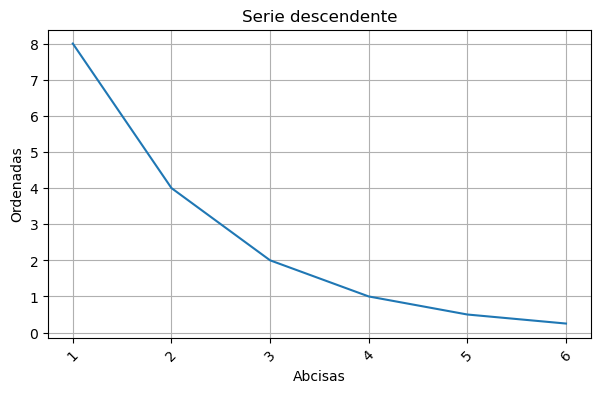

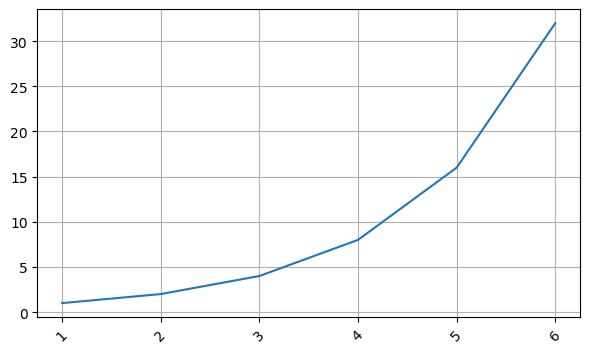

In [33]:
# Pruebas de funcionamiento:

representar_xxx_yyy([(1, 8), (2, 4), (3, 2), (4, 1), (5, 0.5), (6, 0.25)], ["Serie descendente", "Ordenadas", "Abcisas"])

representar_xxx_yyy([(1, 1), (2, 2), (3, 4), (4, 8), (5, 16), (6, 32)])

Salida esperada:

<img src='images/graph_01.png' width='800px' alt='Salida esperada del gráfico anterior: curva descentente y curva ascendente' />

### Una gráfica concreta

Deseamos representar el número de películas de nuestra base de datos que se han producido en un intervalo de años dado.

In [34]:
# Esta celda debe ser completada por el estudiante

def repr_movies_years(data, year_0, year_n):
    """
    Dado un intervalo de años, representa mediante un gráfico lineal el número de películas estrenadas cada año.

    Parámetros:
        data: set de datos de películas.
        year_0: primer año del intervalo de años a representar.
        year_N: último año del intervalo de años a representar.

    Devuelve:
        Gráfico lineal creado mediante la librería matplotlib 
            (eje y: películas presentadas por año
             eje x: año).
    """
    movies_years = years_num_movies(data, year_0, year_n)

    movies_years_orden = []     # Lista ordenada de años

    for key in sorted(movies_years.keys()):         # Ordenamos los años para la representación
        movies_years_orden.append((key, movies_years[key]))

    representar_xxx_yyy(movies_years_orden, ["Number of movies in our database", "num. movies in a year", "years"])

    

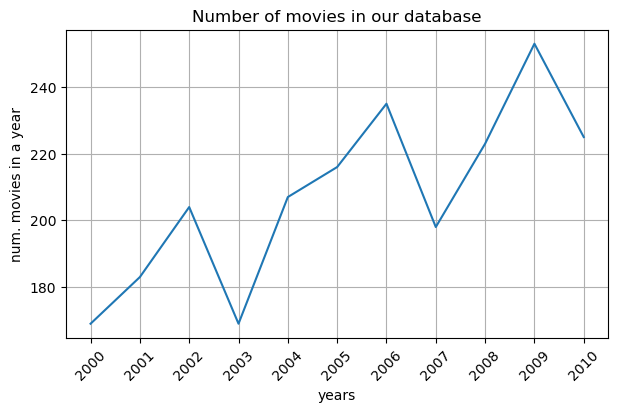

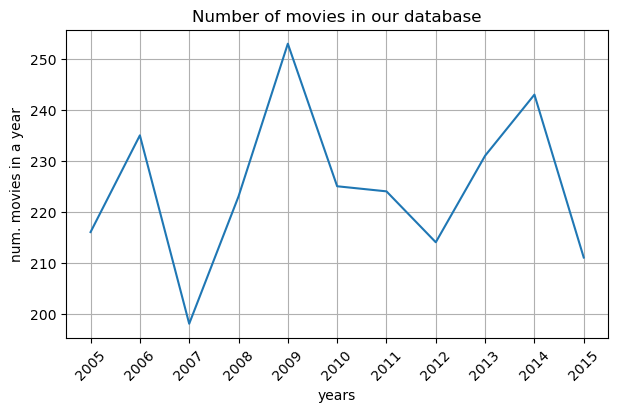

In [35]:
# Test de funcionamiento

repr_movies_years(main_dict_data, 2000, 2010)
repr_movies_years(main_dict_data, 2005, 2015)

Salida esperada:

<img src='images/graph_02.png' width='800px' alt='' />

# D. Acceso a las urls de imdb y webscraping [2 puntos]

### D.1. Recuperación de las URLs

Con sencillas instrucciones, deseamos recuperar todas las *urls* de las películas de nuestro archivo, mostrando cuántas son, la primera de ellas o las diez primeras por ejemplo:

In [36]:
# Esta celda debe ser completada por el estudiante

urls = [pieces[-1] for pieces in main_dict_data.values()]
print(urls)
first_url_movie= urls[0]
first_ten_urls= urls[:10]

['http://www.imdb.com/title/tt0499549/', 'http://www.imdb.com/title/tt0449088/', 'http://www.imdb.com/title/tt2379713/', 'http://www.imdb.com/title/tt1345836/', 'http://www.imdb.com/title/tt5289954/', 'http://www.imdb.com/title/tt0401729/', 'http://www.imdb.com/title/tt0413300/', 'http://www.imdb.com/title/tt0398286/', 'http://www.imdb.com/title/tt2395427/', 'http://www.imdb.com/title/tt0417741/', 'http://www.imdb.com/title/tt2975590/', 'http://www.imdb.com/title/tt0348150/', 'http://www.imdb.com/title/tt0830515/', 'http://www.imdb.com/title/tt0383574/', 'http://www.imdb.com/title/tt1210819/', 'http://www.imdb.com/title/tt0770828/', 'http://www.imdb.com/title/tt0499448/', 'http://www.imdb.com/title/tt0848228/', 'http://www.imdb.com/title/tt1298650/', 'http://www.imdb.com/title/tt1409024/', 'http://www.imdb.com/title/tt2310332/', 'http://www.imdb.com/title/tt0948470/', 'http://www.imdb.com/title/tt0955308/', 'http://www.imdb.com/title/tt1170358/', 'http://www.imdb.com/title/tt0385752/',

In [37]:
# Test de funcionamiento

print(len(urls))

print()

print(first_url_movie) # avatar

print()

print(first_ten_urls)

4919

http://www.imdb.com/title/tt0499549/

['http://www.imdb.com/title/tt0499549/', 'http://www.imdb.com/title/tt0449088/', 'http://www.imdb.com/title/tt2379713/', 'http://www.imdb.com/title/tt1345836/', 'http://www.imdb.com/title/tt5289954/', 'http://www.imdb.com/title/tt0401729/', 'http://www.imdb.com/title/tt0413300/', 'http://www.imdb.com/title/tt0398286/', 'http://www.imdb.com/title/tt2395427/', 'http://www.imdb.com/title/tt0417741/']


Salida esperada:

    4919
    
    http://www.imdb.com/title/tt0499549/
    
    ['http://www.imdb.com/title/tt0499549/', 'http://www.imdb.com/title/tt0449088/', 'http://www.imdb.com/title/tt2379713/', 'http://www.imdb.com/title/tt1345836/', 'http://www.imdb.com/title/tt5289954/', 'http://www.imdb.com/title/tt0401729/', 'http://www.imdb.com/title/tt0413300/', 'http://www.imdb.com/title/tt0398286/', 'http://www.imdb.com/title/tt2395427/', 'http://www.imdb.com/title/tt0417741/']    

### D.2. Carga de la estructura sintáctica de una URL

Ahora, deseamos extraer el código `html` de una película.

In [38]:
# Una forma de evitar el error "Requests 403 forbidden" al hacer web scraping en las siguientes celdas:

HEADERS = {
        "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64; rv:98.0) Gecko/20100101 Firefox/98.0",
        "Accept": "text/html,application/xhtml+xml,application/xml;q=0.9,image/avif,image/webp,*/*;q=0.8",
        "Accept-Language": "en-US,en;q=0.5",
        "Accept-Encoding": "gzip, deflate",
        "Connection": "keep-alive",
        "Upgrade-Insecure-Requests": "1",
        "Sec-Fetch-Dest": "document",
        "Sec-Fetch-Mode": "navigate",
        "Sec-Fetch-Site": "none",
        "Sec-Fetch-User": "?1",
        "Cache-Control": "max-age=0",
    }

In [39]:
# Esta celda debe ser completada por el estudiante

def soup_movie(pelicula):
    """
    Extrae el código html de una página web.  
    
    Parámetros:
        pelicula: url de la página web.

    Devuelve:
        Código html de la página web analizado por BeautifulSoup.
    """
    request = requests.get(pelicula,headers=HEADERS)     # Descargamos la página web con "requests".
    soup = BeautifulSoup(request.content, "html.parser") # Analizamos el html con "BeautifulSoup".
    return soup

In [40]:
# Test de funcionamiento

soup = soup_movie(first_url_movie)

print(str(soup)[:1000])
print()
print("... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ...")
print()
print(str(soup)[-1000:])

<!DOCTYPE html>
<html lang="en-US" xmlns:fb="http://www.facebook.com/2008/fbml" xmlns:og="http://opengraphprotocol.org/schema/"><head><meta charset="utf-8"/><meta content="width=device-width" name="viewport"/><script>if(typeof uet === 'function'){ uet('bb', 'LoadTitle', {wb: 1}); }</script><script>window.addEventListener('load', (event) => {
        if (typeof window.csa !== 'undefined' && typeof window.csa === 'function') {
            var csaLatencyPlugin = window.csa('Content', {
                element: {
                    slotId: 'LoadTitle',
                    type: 'service-call'
                }
            });
            csaLatencyPlugin('mark', 'clickToBodyBegin', 1744303842697);
        }
    })</script><title>Avatar (2009) - IMDb</title><meta content="Avatar: Directed by James Cameron. With Sam Worthington, Zoe Saldaña, Sigourney Weaver, Stephen Lang. A paraplegic Marine dispatched to the moon Pandora on a unique mission becomes torn between following his orders and pr

Salida esperada:

    <!DOCTYPE html>
    <html lang="en-US" translate="no" xmlns:fb="http://www.facebook.com/2008/fbml" xmlns:og="http://opengraphprotocol.org/schema/"><head><meta charset="utf-8"/><meta content="width=device-width" name="viewport"/><script>if(typeof uet === 'function'){ uet('bb', 'LoadTitle', {wb: 1}); }</script><script>window.addEventListener('load', (event) => {
            if (typeof window.csa !== 'undefined' && typeof window.csa === 'function') {
                var csaLatencyPlugin = window.csa('Content', {
                    element: {
                        slotId: 'LoadTitle',
                        type: 'service-call'
                    }
                });
                csaLatencyPlugin('mark', 'clickToBodyBegin', 1738853581913);
            }
        })</script><title>Avatar (2009) - IMDb</title><meta content="Avatar: Directed by James Cameron. With Sam Worthington, Zoe Saldana, Sigourney Weaver, Stephen Lang. A paraplegic Marine dispatched to the moon Pandora on a unique mission becomes torn between following hi
    
    ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ...
    
    g(e+c);return!!e}function n(){for(var e=RegExp("^https://(.*\.(images|ssl-images|media)-amazon\.com|"+c.location.hostname+")/images/","i"),d={},h=0,k=c.performance.getEntriesByType("resource"),l=!1,b,a,m,f=0;f<k.length;f++)if(a=k[f],0<a.transferSize&&a.transferSize>=a.encodedBodySize&&(b=e.exec(String(a.name)))&&3===b.length){a:{b=a.serverTiming||[];for(a=0;a<b.length;a++)if("provider"===b[a].name){b=b[a].description;break a}b=void 0}b&&(l||(l=g(b,"_cdn_fr")),
    a=d[b]=(d[b]||0)+1,a>h&&(m=b,h=a))}g(m,"_cdn_mp")}d.ue&&"function"===typeof d.ue.tag&&c.performance&&c.location&&n()},"cdnTagging")(ue_csm,window);
    
    
    }
    
    /* ◬ */
    </script>
    </div>
    <noscript>
    <img alt="" height="1" src="//fls-na.amazon.com/1/batch/1/OP/A1EVAM02EL8SFB:130-1575513-7998461:SMWGHB497V5D4NRH3FAY$uedata=s:%2Fuedata%2Fuedata%3Fnoscript%26id%3DSMWGHB497V5D4NRH3FAY:0" style="display:none;visibility:hidden;" width="1"/>
    </noscript>
    <script>window.ue && ue.count && ue.count('CSMLibrarySize', 61663)</script></div></body></html>

### D.3. Extracción de algunas piezas de información de una URL

Y ahora, con dicho código, deseamos extraer la siguiente información, referida a la película `first_url_movie`:

- La etiqueta completa del título de la película
- La descripción (sólo el contenido).
- La lista de actores
- La información sobre el presupuesto

In [41]:
# Esta celda debe ser completada por el estudiante

print(soup.find("title"))   # Encontrado usando el visualizador de html F12 en Google Chrome

for tag in soup.find_all("meta"): 
    if tag.get("name") == "description":
        print(tag.get("content"))

actors = []
for a in soup.find_all("a", attrs={"data-testid": "title-cast-item__actor"}):
    a=a.get_text(strip=True)
    actors.append(a)
    
print(actors)

print(soup.find_all("span", attrs={"class":"ipc-metadata-list-item__list-content-item ipc-btn--not-interactable", "aria-disabled":"false"})[2].get_text())

<title>Avatar (2009) - IMDb</title>
Avatar: Directed by James Cameron. With Sam Worthington, Zoe Saldaña, Sigourney Weaver, Stephen Lang. A paraplegic Marine dispatched to the moon Pandora on a unique mission becomes torn between following his orders and protecting the world he feels is his home.
['Sam Worthington', 'Zoe Saldaña', 'Sigourney Weaver', 'Michelle Rodriguez', 'Stephen Lang', 'Giovanni Ribisi', 'Joel David Moore', 'CCH Pounder', 'Wes Studi', 'Laz Alonso', 'Dileep Rao', 'Matt Gerald', 'Sean Anthony Moran', 'Jason Whyte', 'Scott Lawrence', 'Kelly Kilgour', 'James Patrick Pitt', 'Sean Patrick Murphy']
$237,000,000 (estimated)


Salida esperada:

    <title>Avatar (2009) - IMDb</title>
    
    Avatar: Directed by James Cameron. With Sam Worthington, Zoe Saldana, Sigourney Weaver, Stephen Lang. A paraplegic Marine dispatched to the moon Pandora on a unique mission becomes torn between following his orders and protecting the world he feels is his home.
    
    ['Sam Worthington', 'Zoe Saldana', 'Sigourney Weaver', 'Michelle Rodriguez', 'Stephen Lang', 'Giovanni Ribisi', 'Joel David Moore', 'CCH Pounder', 'Wes Studi', 'Laz Alonso', 'Dileep Rao', 'Matt Gerald', 'Sean Anthony Moran', 'Jason Whyte', 'Scott Lawrence', 'Kelly Kilgour', 'James Patrick Pitt', 'Sean Patrick Murphy']
    
    $237,000,000 (estimated)

### D.4. Actores que intervienen en una lista de URLs

Necesitamos crear un archivo con los actores de las películas de IMDB, dada la lista de sus URLs.

In [42]:
# Esta celda debe ser completada por el estudiante

def gather_actors(archivo, urls):
    """ 
    Consigue y redacta en un archivo .txt el nombre de los actores de una película.
    
    Parámetros:
        archivo: nombre del archivo que queremos escribir.
        urls: /s o urls de la/s película/s de la que queremos conseguir los nombres de actores.
    
    Devuelve:
        Archivo .txt con los nombres de los actores.
    """
    with open(archivo, "w", encoding="utf-8") as file: 
        for url in urls:                                    # Para el url de cada película
            request = requests.get(url, headers=HEADERS)    # Descarga la página con request
            soup = BeautifulSoup(request.content, "html.parser")    # Analiza el request con BeautifulSoup
            actores = soup.find_all("a", attrs={"data-testid": "title-cast-item__actor"})
            
            for actor in actores:
                file.write(f"{actor.text.strip()}\n")


In [43]:
# Test de funcionamiento

# OJO: esta operación puede llevar bastante tiempo.
# Para esta prueba, usamos un número limitado de películas.

gather_actors("actors_3_first_movies.txt", urls[:3])

with open("actors_3_first_movies.txt") as f:
    for _ in range(10):
        line = f.readline().strip()
        print(line)

Sam Worthington
Zoe Saldaña
Sigourney Weaver
Michelle Rodriguez
Stephen Lang
Giovanni Ribisi
Joel David Moore
CCH Pounder
Wes Studi
Laz Alonso


Salida esperada:

    Sam Worthington
    Zoe Saldana
    Sigourney Weaver
    Michelle Rodriguez
    Stephen Lang
    Giovanni Ribisi
    Joel David Moore
    CCH Pounder
    Wes Studi
    Laz Alonso

In [44]:
# La siguente llamada llevaría un tiempo realmente largo:

# import time # para cronometrar esta función, que tarda mucho

# reloj_inicio = time.time()
# gather_actors("actors_all_movies.txt", urls)
# reloj_fin = time.time()

# print("Tiempo invertido: %s segundos." % (reloj_fin - reloj_inicio))

# E. Pandas [2 puntos]

### E.1. El primer paso es la carga del archivo en un dataframe

In [45]:
# Esta celda debe ser completada por el estudiante
def load_dataframe(data):
    """
    Carga un archivo CSV en un dataframe de Pandas.
    
    Parámetros:
        data: ruta del archivo CSV.
    
    Devuelve:
        Dataframe de Pandas con el archivo CSV cargado.
    """
    archivo_pd = pd.read_csv(data) # Leemos el CSV con Pandas.
    return archivo_pd

In [46]:
# Test de funcionamiento

tabla_completa = load_dataframe(MOVIES_DATA)

tabla_completa

,color,director_name,num_critic_for_reviews,duration,director_facebook_likes,actor_3_facebook_likes,actor_2_name,actor_1_facebook_likes,gross,genres,...,num_user_for_reviews,language,country,content_rating,budget,title_year,actor_2_facebook_likes,imdb_score,aspect_ratio,movie_facebook_likes
0,Color,James Cameron,723.0,178.0,0.0,855.0,Joel David Moore,1000.0,760505847.0,Action|Adventure|Fantasy|Sci-Fi,...,3054.0,English,USA,PG-13,237000000.0,2009.0,936.0,7.9,1.78,33000
1,Color,Gore Verbinski,302.0,169.0,563.0,1000.0,Orlando Bloom,40000.0,309404152.0,Action|Adventure|Fantasy,...,1238.0,English,USA,PG-13,300000000.0,2007.0,5000.0,7.1,2.35,0
2,Color,Sam Mendes,602.0,148.0,0.0,161.0,Rory Kinnear,11000.0,200074175.0,Action|Adventure|Thriller,...,994.0,English,UK,PG-13,245000000.0,2015.0,393.0,6.8,2.35,85000
3,Color,Christopher Nolan,813.0,164.0,22000.0,23000.0,Christian Bale,27000.0,448130642.0,Action|Thriller,...,2701.0,English,USA,PG-13,250000000.0,2012.0,23000.0,8.5,2.35,164000
4,NaN,Doug Walker,NaN,NaN,131.0,NaN,Rob Walker,131.0,NaN,Documentary,...,NaN,NaN,NaN,NaN,NaN,NaN,12.0,7.1,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5038,Color,Scott Smith,1.0,87.0,2.0,318.0,Daphne Zuniga,637.0,NaN,Comedy|Drama,...,6.0,English,Canada,NaN,NaN,2013.0,470.0,7.7,NaN,84
5039,Color,NaN,43.0,43.0,NaN,319.0,Valorie Curry,841.0,NaN,Crime|Drama|Mystery|Thriller,...,359.0,English,USA,TV-14,NaN,NaN,593.0,7.5,16.00,32000
5040,Color,Benjamin Roberds,13.0,76.0,0.0,0.0,Maxwell Moody,0.0,NaN,Drama|Horror|Thriller,...,3.0,English,USA,NaN,1400.0,2013.0,0.0,6.3,NaN,16
5041,Color,Daniel Hsia,14.0,100.0,0.0,489.0,Daniel Henney,946.0,10443.0,Comedy|Drama|Romance,...,9.0,English,USA,PG-13,NaN,2012.0,719.0,6.3,2.35,660


Salida esperada:

<img src='images/df_01.png' width='800px' alt='' />

### E.2. Tabla de los campos principales

A pertir de la tabla anterior, construimos otra con sólo algumos de los campos:

In [47]:
# Esta celda debe ser completada por el estudiante

def fields_selected_dataframe(tabla_completa):
    """
    Selecciona los campos que mostrar de un dataframe.

    Parámetros:
         tabla_completa: dataframe de Pandas input.
    
    Devuelve:
        Dataframe de Pandas input filtrado con las columnas seleccionadas.
    
    """
    return tabla_completa[["movie_title", "color", "director_name", "language", "country", "actor_1_name", "movie_imdb_link"]]

In [48]:
# test de comprobación

tabla_breve = fields_selected_dataframe(tabla_completa)

tabla_breve

,movie_title,color,director_name,language,country,actor_1_name,movie_imdb_link
0,Avatar,Color,James Cameron,English,USA,CCH Pounder,http://www.imdb.com/title/tt0499549/?ref_=fn_t...
1,Pirates of the Caribbean: At World's End,Color,Gore Verbinski,English,USA,Johnny Depp,http://www.imdb.com/title/tt0449088/?ref_=fn_t...
2,Spectre,Color,Sam Mendes,English,UK,Christoph Waltz,http://www.imdb.com/title/tt2379713/?ref_=fn_t...
3,The Dark Knight Rises,Color,Christopher Nolan,English,USA,Tom Hardy,http://www.imdb.com/title/tt1345836/?ref_=fn_t...
4,Star Wars: Episode VII - The Force Awakens ...,NaN,Doug Walker,NaN,NaN,Doug Walker,http://www.imdb.com/title/tt5289954/?ref_=fn_t...
...,...,...,...,...,...,...,...
5038,Signed Sealed Delivered,Color,Scott Smith,English,Canada,Eric Mabius,http://www.imdb.com/title/tt3000844/?ref_=fn_t...
5039,The Following,Color,NaN,English,USA,Natalie Zea,http://www.imdb.com/title/tt2071645/?ref_=fn_t...
5040,A Plague So Pleasant,Color,Benjamin Roberds,English,USA,Eva Boehnke,http://www.imdb.com/title/tt2107644/?ref_=fn_t...
5041,Shanghai Calling,Color,Daniel Hsia,English,USA,Alan Ruck,http://www.imdb.com/title/tt2070597/?ref_=fn_t...


Salida esperada:

<img src='images/df_02.png' width='800px' alt='' />

### E.3. Columnas de una tabla

¿Cuáles son las columnas de nuestrsa `tabla_breve`?

In [49]:
# Esta celda debe ser completada por el estudiante

tabla_breve.columns

Index(['movie_title', 'color', 'director_name', 'language', 'country',
       'actor_1_name', 'movie_imdb_link'],
      dtype='object')

Salida esperada:

    Index(['movie_title', 'color', 'director_name', 'language', 'country',
           'actor_1_name', 'movie_imdb_link'],
          dtype='object')

### E.4. Campos missing

Algunos campos muestran un valod `NaN`. Deseamos cambiarlo por una cadena de caracteres: `"Desc"`.

In [50]:
# Esta celda debe ser completada por el estudiante

tabla_breve = tabla_breve.fillna("Desc")

In [51]:
# Test de comprobación

tabla_breve

,movie_title,color,director_name,language,country,actor_1_name,movie_imdb_link
0,Avatar,Color,James Cameron,English,USA,CCH Pounder,http://www.imdb.com/title/tt0499549/?ref_=fn_t...
1,Pirates of the Caribbean: At World's End,Color,Gore Verbinski,English,USA,Johnny Depp,http://www.imdb.com/title/tt0449088/?ref_=fn_t...
2,Spectre,Color,Sam Mendes,English,UK,Christoph Waltz,http://www.imdb.com/title/tt2379713/?ref_=fn_t...
3,The Dark Knight Rises,Color,Christopher Nolan,English,USA,Tom Hardy,http://www.imdb.com/title/tt1345836/?ref_=fn_t...
4,Star Wars: Episode VII - The Force Awakens ...,Desc,Doug Walker,Desc,Desc,Doug Walker,http://www.imdb.com/title/tt5289954/?ref_=fn_t...
...,...,...,...,...,...,...,...
5038,Signed Sealed Delivered,Color,Scott Smith,English,Canada,Eric Mabius,http://www.imdb.com/title/tt3000844/?ref_=fn_t...
5039,The Following,Color,Desc,English,USA,Natalie Zea,http://www.imdb.com/title/tt2071645/?ref_=fn_t...
5040,A Plague So Pleasant,Color,Benjamin Roberds,English,USA,Eva Boehnke,http://www.imdb.com/title/tt2107644/?ref_=fn_t...
5041,Shanghai Calling,Color,Daniel Hsia,English,USA,Alan Ruck,http://www.imdb.com/title/tt2070597/?ref_=fn_t...


Salida esperada:

<img src='images/df_03.png' width='800px' alt='' />

### E.5. Director $\rightarrow$ películas y número de películas

Función que averigua la lista de títulos de películas de un director dado:

In [52]:
# Esta celda debe ser completada por el estudiante

def titulos_de_director_df(data_pd, director):
    """
    Muestra las películas de un director.

    Parámetros:
        data_pd: Dataframe de Pandas input.
        director: Director de quien se quieren consultar sus películas (tipo string) 

    Devuelve:
        Columna de Pandas con los títulos de película del director filtrado y el índice de cada película. 
    """
    data_filt = data_pd.loc[data_pd['director_name'] == director, ["movie_title"]] 
    
    return data_filt



In [53]:
# Test de comprobación:

tabla_tits = titulos_de_director_df(tabla_breve, "James Cameron")
tabla_tits

,movie_title
0,Avatar
26,Titanic
288,Terminator 2: Judgment Day
291,True Lies
606,The Abyss
2486,Aliens
3575,The Terminator


Salida esperada:

<img src='images/df_04.png' width='800px' alt='' />

In [54]:
list_tits = tabla_tits["movie_title"].to_list()
print(list_tits)

['Avatar\xa0', 'Titanic\xa0', 'Terminator 2: Judgment Day\xa0', 'True Lies\xa0', 'The Abyss\xa0', 'Aliens\xa0', 'The Terminator\xa0']


Salida esperada:

    ['Avatar\xa0', 'Titanic\xa0', 'Terminator 2: Judgment Day\xa0', 'True Lies\xa0', 'The Abyss\xa0', 'Aliens\xa0', 'The Terminator\xa0']

¿Qué directores han dirigido más de *n* películas?

In [55]:
# Esta celda debe ser completada por el estudiante

# Esta pregunta debe estar mal formulada, necesariamente debería de poderse fijar la n como parámetro de la función (no aparece en la función test)
# La función test está mal planteada conforme a la pregunta.

def directors_max_movies_df(data_pd, n):
    """
    Muestra los directores con más de "n" películas en el dataset.

    Parámetros:
        data_pd: Dataframe de Pandas input.
        n: número de mínimo de películas dirigidas por cada director (filtro de directores).
    Devuelve:
        Diccionario con clave: los directores con más de "n" publicaciones; y valor: número de publicaciones.
    """

    data_filt = data_pd[data_pd['director_name'] != 'Desc'] # Filtramos directores con valor nulo
    conteo = data_filt['director_name'].value_counts()  # Conteo de veces que aparece cada director
    filtrado = conteo[conteo > n]   # Filtro de número de apariciones.
    return filtrado.to_dict()


In [56]:
# test de comprobación:

#directors_max_movies_df(tabla_breve)

directors_max_movies_df(tabla_breve, 18)

{'Steven Spielberg': 26,
 'Woody Allen': 22,
 'Clint Eastwood': 20,
 'Martin Scorsese': 20}

Salida esperada:

    (['Steven Spielberg'], np.int64(26))

# Parte F. [0,5 puntos]

## Opción 1. Un cálculo con MRJob

En este apartado se ha de realizar un programa aparte, *basado en la técnica de map-reduce*, que calcule, para cada idioma, en qué países en que se han producido películas y la suma de los presupuestos de dichas películas. Cuando el idioma o el país o el presupuesto no se conozcan, no se considerará esta película.

    C:\...> python language_budget_countries.py -q algunos_campos.txt

El programa funcionará necesariamente con la técnica map-reduce, que podemos poner en juego con la librería `mrjob`.

El funcionamiento del mismo se puede activar también desde aquí:


In [79]:
# Hagamos una llamada al programa de consola desde aquí:

! python language_budget_countries.py -q algunos_campos.txt

Traceback (most recent call last):
  File "c:\Users\ppabl\Desktop\TAREA PYTHON\language_budget_countries.py", line 28, in <module>
    main()
  File "c:\Users\ppabl\Desktop\TAREA PYTHON\language_budget_countries.py", line 11, in main
    tabla_completa= data_pd
                    ^^^^^^^
UnboundLocalError: cannot access local variable 'data_pd' where it is not associated with a value


In [80]:
# Para que el resultado se almacene en un archivo:

! python language_budget_countries.py -q algunos_campos.txt > language_countries_budgets.txt

Traceback (most recent call last):
  File "c:\Users\ppabl\Desktop\TAREA PYTHON\language_budget_countries.py", line 28, in <module>
    main()
  File "c:\Users\ppabl\Desktop\TAREA PYTHON\language_budget_countries.py", line 11, in main
    tabla_completa= data_pd
                    ^^^^^^^
UnboundLocalError: cannot access local variable 'data_pd' where it is not associated with a value


Para que pueda yo ver tu programa cómodamente desde aquí, también se puede mostrar con un comando de la consola, anteponiendo el símbolo `!`. Observaciones:

- La instrucción siguiente está comentada para ocultar una solución mía.
  Tú debes suprimir el símbolo `#` del comentario
  para mostrar tu solución aquí.
- Desde mac o linux, se ha de usar el comando `cat`, en vez de `type`.

In [81]:
! type language_budget_countries.py

def language_budget_countries(data_pd):
    """
    Muestra los países en que han sido presentadas y el presupuesto conjunto del grupo de películas de cada idioma.
    
    Parámetros:
        data_pd: Dataframe de Pandas.

    Devuelve:
        Dataframe de Pandas con las columnas: "language", "countries" y "total_budget".
    """
    data_pd = data_pd.fillna("Desc")  # Rellena valores nulos con el valor "Desc" (paso para la coherencia con tablas de la tarea)
    data_filt = data_pd[(data_pd["budget"] != "Desc") & (data_pd["country"] != "Desc") & (data_pd["language"] != "Desc")][["budget","country", "language"]] # Filtro de valores nulos y selección de columnas

    data_grouped = data_filt.groupby("language") # Agrupamos el pandas por "language"

    data_final = pd.DataFrame(
        map(lambda data: { # Uso de map para aplicar los cambios a cada grupo de datos
            "language": data[0],        
            "countries": list(data[1]["country"].unique()), # creamos una columna nueva a partir de los valores únicos de "country" para cada lengua.
            "total_budget": reduce(lambda x, y: x + y, data[1]["budget"]) # reduce suma los valores de la columna "budget" agrupados por lengua.
        }, data_grouped)) 
    
    return data_final.sort_values(by="total_budget",ascending=False) # Mostramos los valores por valor del presupuesto total en orden descendente.

def main():
    """
    Muestra los países en que han sido presentadas y el presupuesto conjunto del grupo de películas de cada idioma.
    
    Parámetros:
        data_pd: Dataframe de Pandas.

    Devuelve:
        Dataframe de Pandas con las columnas: "language", "countries" y "total_budget".
    """
    tabla_completa= data_pd
    data_pd = data_pd.fillna("Desc")  # Rellena valores nulos con el valor "Desc" (paso para la coherencia con tablas de la tarea)
    data_filt = data_pd[(data_pd["budget"] != "Desc") & (data_pd["country"] != "Desc") & (data_pd["language"] != "Desc")][["budget","country", "language"]] # Filtro de valores nulos y selección de columnas

    data_grouped = data_filt.groupby("language") # Agrupamos el pandas por "language"

    data_final = pd.DataFrame(
        map(lambda data: { # Uso de map para aplicar los cambios a cada grupo de datos
            "language": data[0],        
            "countries": list(data[1]["country"].unique()), # creamos una columna 

In [82]:
language_budget_countries(tabla_completa)

,language,countries,total_budget
11,English,"[USA, UK, New Zealand, Canada, Australia, Germ...",1.486341e+11
23,Korean,[South Korea],1.644930e+10
21,Japanese,"[Japan, USA]",6.801920e+09
17,Hungarian,[Hungary],2.500000e+09
24,Mandarin,"[China, Hong Kong, Taiwan]",1.230632e+09
13,French,"[France, Canada, Finland, UK]",1.039754e+09
16,Hindi,"[India, USA]",1.027668e+09
34,Spanish,"[USA, Mexico, Spain, Italy, Argentina, Colombi...",9.513258e+08
39,Thai,[Thailand],9.000000e+08
4,Cantonese,"[Hong Kong, China]",1.545000e+08


## Opción 2. Cálculo con 

# Parte G. Un apartado libre [0.5 puntos]


<br>

<font color="darkblue">
Tras eliminar el párrafo anterior, en verde, completa tú aquí este enunciado, cuya fuetne aparecerá en azul oscuro.

Vamos a estudiar cuales son los países con mayor número de directores, visualizaremos la información utilizando la libreria geopandas.
</font>

In [83]:
# Pruebas de funcionamiento, también tarea del estudiante:



# Datos personales

<br>

<font color="darkblue">

-   **Apellidos:** Vicente González
-   **Nombre:** Pedro Pablo
-   **Email:** pedropablovicenteg@gmail.com
-   **Fecha:** 10/04/2025

<br>

<font color="black">
    
### Ficha de autoevaluación


<br>

<font color="darkblue">
    
|Apartado|Calificación|Comentario|
|-|-|-|
|a)  |2.5  / 2.5  |Completamente resuelto y explicado |
|b)  |2.0  / 2.0  |Completamente resuelto y explicado |
|c)  |1.5  / 1.5  |Completamente resuelto y explicado |
|d)  |0.90 / 1.0  |Completamente resuelto y explicado, código algo caótico en apartado D.3. |
|e)  |2.0  / 2.0  |Completamente resuelto y explicado, última pregunta (E.5.) corregida (ver anotaciones en la pregunta) |
|f)  |0.2  / 0.5  |He conseguido un código que ofrece la respueta que se pide pero no he conseguido desarrollar las ejecuciones mediante consola |
|g)  |0.0  / 0.5  |No presentada |
|**Total** |**9.1** / 10.0|**Aprobado**|
</font>

<br>

<font color="black">
   
### Ayuda recibida y fuentes utilizadas
    
</font>

<br>

<font color="darkblue">

La forma en la que he operado para hacer los ejercicios ha sido: si no sé plantear algo lo busco en los apuntes de clase y, si entre las diapositivas y mis apuntes personales no hay ideas que me sirvan de ayuda, paso a la documentación oficial de Python (la que aparece siempre al final de los apuntes). Esta forma de trabajar ha sido especialmente útil en los dos primeros apartados. Lo cierto es que tampoco hay muchas ideas cogidas de fuera.

Lo que si he cogido de fuera son estructuras de código que ya sé que voy a tener de forma accesible en foros web como Stack Overflow, W3 Schools o Reddit; estrcuturas de código como el de los gráficos de Matplotlib, el uso de "open" para lectura y escritura de archivos (sé que parece obvio pero no es código que utilice todos los días), o el uso conjunto entre requests y BeautifulSoup. En estos casos he buscado directamente en Google, he accedido a los foros y he visto cómo funcionan con ejemplos reales. 

</font>

<br>

<font color="black">
    
### Comentario adicional

</font>

<br>

<font color="darkblue">

Algunos apuntes individuales que quiero hacer sobre los ejercicios son:
<br>

-"B.2. Recuperación de alguna información": No sé si con el test de funcionamiento proporcionado debería aparecer en la solución la ruta de escritura "data_in/algunos_campos.txt", según la salida esperada sí.
<br>

-En el apartado E.5 la pregunta "¿Qué directores han dirigido más de *n* películas?" debe de estar mal planteada puesto que, en el test de funcionamiento, la función no tiene ningún parámetro que sea "n películas como mínimo". Por ello he aportado mi propia función de test.

Honestamente, no sé si me han sido de ayuda o, por el contrario, me ha costado algo más resolver algún apartado a causa de los test de funcionamiento. Estas sensaciones mixtas se deben a que, más allá de que me hayan podido ser o no útiles, hacen que la respuesta se condicione a una serie de inputs y a una serie de resultados (la salida esperada). El ejemplo más claro ha sido el apartado E.5. donde la pregunta y la respuesta pedidas, defiendo, no tienen coherencia; pero hablo de haber sentido que hacía una especie de ingeniería inversa, son casos como el apartado B.2., en la pregunta "¿Qué directores han dirigido el número máximo de películas?" mi resultado es correcto pero el nombre del director no sale entre corchetes (esa es la máxima holgura que he encontrado en sentirme libre al buscar respuestas). Otras salidas esperadas son muy obvias o salen a la primera y sin buscarlo. Por otra parte, entiendo, esta estructura de ejercicios se debe a razones de corrección, es mucho temario sobre el que calificar.

El tiempo es otra observación importante, tal vez de haber tenido contactos previos con Python algo más serios hubiese tardado menos en hacer la tarea. No me ha dado tiempo ha hacer la última pregunta y, de tener un trabajo con jornada completa, no me hubiese dado tiempo a hacer los últimos ejercicios (o hubiese saltado los ejercicios de diccionarios). 

En cuanto a la última pregunta, quería proponer una visualización mediante Geopandas (de cualquier dato en realidad), solo para conseguir algo más de nota, pero finalmente no he podido. En primer lugar, porque es día 10/04 y me quedo sin tiempo; en segundo lugar, porque estoy teniendo un problema a la hora de importar las librerias de mapeado (no me ha funcionado geopandas, folium ni leaflet debido al error "ModuleNotFoundError: no module named {librería}"). Habiéndolo instalado incluso en distintos entornos de Python he concluído que tal vez sea un error del intérprete de Python, lo cierto es que no lo he conseguido solucionar.

</font>

In [84]:
# Esta celda se ha de respetar: está aquí para comprobar el funcionamiento de algunas funciones por parte de tu profesor

import sys
modulenames = set(sys.modules) & set(globals())

if "mrjob" in modulenames:
    print("* En las librerías importadas, la siguiente no es necesaria\n" +
          "      from mrjob.job import MRJob\n" +
          "  porque no va a usarse en el cuaderno, sino en un programa externo. Debe omitirse aquí.\n")

from os.path import exists

if not exists("./images/"):
    print("* He echado de menos la carpeta 'images'.\n")

# ----------------------------------------------------------------------------

if not 'defaultdict' in set(globals()) and not 'collections' in modulenames:
    print("El uso de diccionarios por defecto es muy importante y te recomiendo que te familiarices con ellos.")

# ----------------------------------------------------------------------------

nombres = dir()

# Constantes: .....................

# print("----------------- Constantes")

const_names_asked = ["MOVIES_DATA", "FEW_FIELDS"]
for const_name in const_names_asked:
    if const_name not in nombres:
        print("La constante '" + const_name + "' no se ha definido.\n")

# Funciones: .....................

# print("----------------- Funciones")

name_funcs_asked = ["load_full_data", "main_data_from_item", "datatypes_arranged", "load_main_data",
                    "movies_anno_for_director", "directors_max_movies", "years_num_movies", "store_file",
                    "actor_directors", "print_collaborations_min", "representar_xxx_yyy", "gather_actors",
                    "load_dataframe", "titulos_de_director_df", "directors_max_movies_df"]

name_funcs_defined = [f for f in name_funcs_asked if f in nombres]

name_funcs_not_defined = [f for f in name_funcs_asked if f not in nombres]

def comentario(frase, nombres) -> str:
    if nombres != []:
        print(frase + ": " + ", ".join(nombres) + ".\n")

comentario("Las funciones siguientes no están definidas: ", name_funcs_not_defined)

# Variables: .....................

# print("----------------- Variables")

name_vars_asked = ["full_header", "list_of_enumerated_headers", "datos_avatar_2009", "datos_star_wars_7",
                   "colores", "pelis_victor", "main_header", "main_dict_data", "num_movies", "num_movies_sorted",
                   "num_collaborations", "first_url_movie", "first_ten_urls", "response", "soup", "actors",
                   "presupuesto_apartado", "presupuesto_importe", "importe_str",
                   "tabla_breve", "tabla_tits", "list_tits"]

name_vars_not_defined = [v for v in name_vars_asked if v not in nombres]

comentario("Las variables siguientes no están calculadas: ", name_vars_not_defined)
              
# ----------------------------------------------------------------------------

# Funciones definidas: .....................

# print("----------------- Funciones definidas. Semántica")

funcs_defined = [globals()[f_name] for f_name in name_funcs_defined]

# print(funcs_defined)

# print("..............................................................................")

no_docstrings = [f.__name__ for f in funcs_defined if f.__doc__ is None]
comentario("Las funciones siguientes no tienen el docstring estándar: " , no_docstrings)

# print("..............................................................................")

escasos_docstrings = [f.__name__ for f in funcs_defined if f.__doc__ is not None and len(f.__doc__.split("\n")) < 2]
comentario("El docstring de las funciones siguientes es insuficiente: ", escasos_docstrings)

# print("----------------- Funcs. open sin contexto")

import inspect

fs_open_close = [f for f in name_funcs_defined
                 if "= open" in inspect.getsource(globals()[f])
                 or "=open" in inspect.getsource(globals()[f])]

comentario("* El manejo de archivos es mejor con un contexto 'with ...' en lugar de con open-close. " +
           "V. funciones siguientes", fs_open_close)

# print("----------------- Funcs. with readlines()")

fs_with_readlines = [f for f in funcs_defined if "readlines" in inspect.getsource(f)]

comentario("* La instrucción 'readlines()' carga un archivo entero en la memoria principal. " +
           "Esto conlleva un gasto de memoria realmente grande, " +
           "innecesario cuando sólo interesa una línea, o cuando puede procesarse " +
           "línea a línea. " +
           "Las siguientes funciones contienen la instrucción 'readlines'", fs_with_readlines)

# ----------------------------------------------------------------------------

if not exists("./language_budget_countries.py"):
    print("* El programa de map-reduce no está hecho. Te recomiendo " +
          "fuertemente que inviertas algún tiempo en él, pues los conceptos " +
          "que trata son importantes en el mundo de la ciencia de datos.")

Las funciones siguientes no están definidas: : print_collaborations_min.

Las variables siguientes no están calculadas: : response, presupuesto_apartado, presupuesto_importe, importe_str.

